<a href="https://colab.research.google.com/github/HunRajveer/ML/blob/main/HeartDiseasePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from  sklearn.metrics import accuracy_score , f1_score , classification_report , confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
df = pd.read_csv("heart.csv")

In [ ]:
df.head(10)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [ ]:
df.value_counts('ChestPainType')

,count
ChestPainType,
ASY,496
NAP,203
ATA,173
TA,46


<Axes: xlabel='Age', ylabel='Count'>

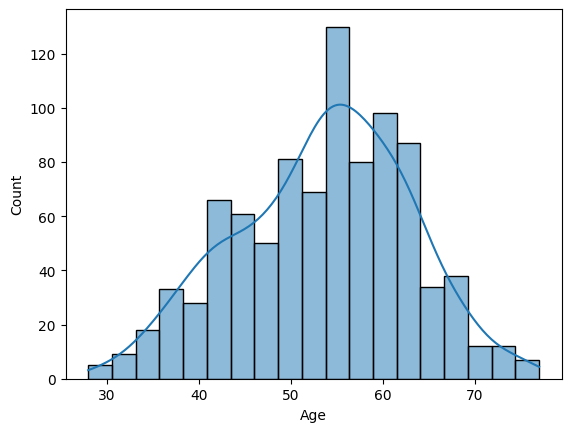

In [ ]:
sns.histplot(data = df , x  = 'Age',kde = True)

<Axes: xlabel='Cholesterol', ylabel='Count'>

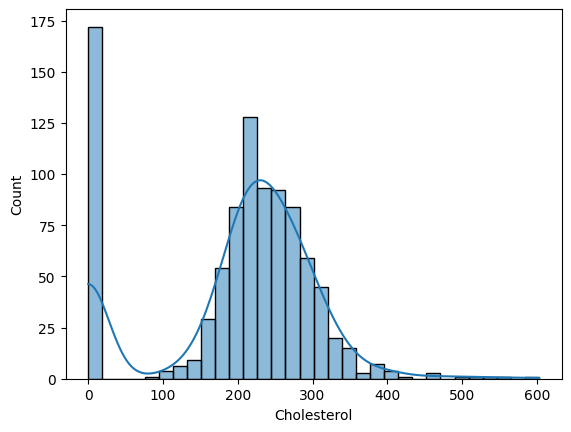

In [ ]:
sns.histplot(data = df , x  = 'Cholesterol',kde = True)

<Axes: xlabel='MaxHR', ylabel='Count'>

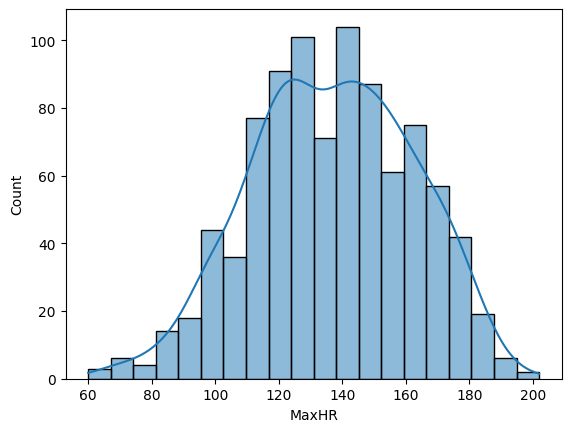

In [ ]:
sns.histplot(data = df , x  = 'MaxHR',kde = True)

<Axes: xlabel='Age', ylabel='MaxHR'>

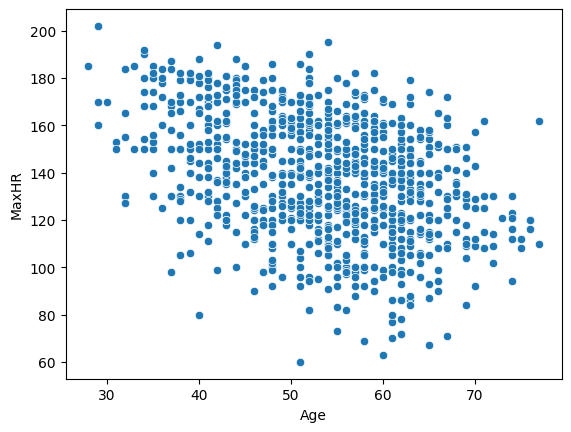

In [ ]:
sns.scatterplot(data = df , x = 'Age' , y = 'MaxHR')

In [ ]:
x = df.corr(numeric_only = True )

<Axes: >

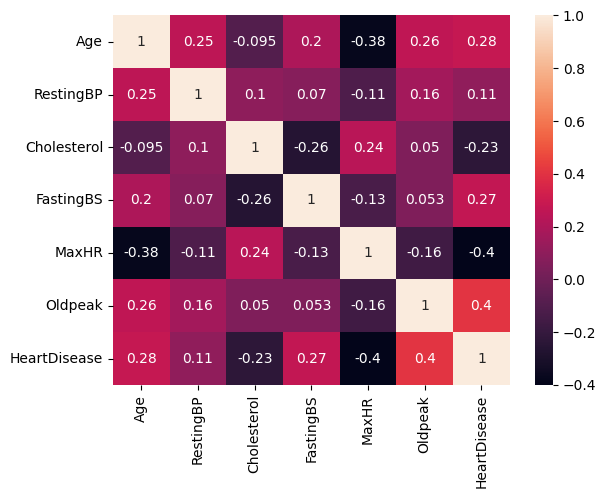

In [ ]:
sns.heatmap(x, annot = True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [ ]:
from sklearn.preprocessing import LabelEncoder
encoder =  LabelEncoder()

In [ ]:
column = ['Sex','ST_Slope','Sex','ChestPainType','RestingECG','ExerciseAngina']
for col in column:
  df[col] = encoder.fit_transform(df[col])

In [ ]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,3,110,264,0,1,132,0,1.2,1,1
914,68,1,0,144,193,1,1,141,0,3.4,1,1
915,57,1,0,130,131,0,1,115,1,1.2,1,1
916,57,0,1,130,236,0,0,174,0,0.0,1,1


In [ ]:
scaler = StandardScaler()
scaled_df = scaler.fit_transform(df)

In [ ]:
scaled_df

array([[-1.4331398 ,  0.51595242,  0.22903206, ..., -0.83243239,
         1.05211381, -1.11311472],
       [-0.47848359, -1.93816322,  1.27505906, ...,  0.10566353,
        -0.59607813,  0.89837999],
       [-1.75135854,  0.51595242,  0.22903206, ..., -0.83243239,
         1.05211381, -1.11311472],
       ...,
       [ 0.37009972,  0.51595242, -0.81699495, ...,  0.29328271,
        -0.59607813,  0.89837999],
       [ 0.37009972, -1.93816322,  0.22903206, ..., -0.83243239,
        -0.59607813,  0.89837999],
       [-1.64528563,  0.51595242,  1.27505906, ..., -0.83243239,
         1.05211381, -1.11311472]])

In [ ]:
x = df.drop('HeartDisease', axis = 1)
y = df['HeartDisease']

In [ ]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size = 0.23,random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree  import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB


In [ ]:
model = {
    'LogisticRegression' : LogisticRegression(),
    'DecisionTreeClassifier' : DecisionTreeClassifier(),
    'KNeighborsClassifier' : KNeighborsClassifier(),
    'SVC' : SVC(),
    'GaussianNB' : GaussianNB()
}

In [ ]:
result = []

In [ ]:
for name , models in model.items():
  models.fit(xtrain,ytrain)
  ypredict = models.predict(xtest)
  acc = accuracy_score(ytest, ypredict)
  f1 = f1_score(ytest, ypredict)
  result.append({
      'Model' : name,
      'Accuracy' :round(acc,4),
      'F1 Score' : round(f1,4)
  })


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
result

[{'Model': 'LogisticRegression', 'Accuracy': 0.8491, 'F1 Score': 0.8632},
 {'Model': 'DecisionTreeClassifier', 'Accuracy': 0.7736, 'F1 Score': 0.7913},
 {'Model': 'KNeighborsClassifier', 'Accuracy': 0.7075, 'F1 Score': 0.7395},
 {'Model': 'SVC', 'Accuracy': 0.7028, 'F1 Score': 0.7319},
 {'Model': 'GaussianNB', 'Accuracy': 0.8538, 'F1 Score': 0.8703}]

In [ ]:
# we have best accuracy of GaussianNB 85% so we will use this model
# so will covert model into pickel file
import joblib
joblib.dump(model['GaussianNB'],'GaussianNB.pkl')
joblib.dump(scaler,'scaler.pkl')
joblib.dump(x.columns.tolist(),'columns.pkl')

['columns.pkl']